# Pose-Based Recognition of Indian Sign Language using Deep Learning on the iSign Dataset

**Reorganised experimental notebook — Google Colab**

## Updated research question
Can pose-based representations support low-resource Indian Sign Language processing by combining (i) motion-activity analysis on continuous iSign clips and (ii) one-shot prototype matching for isolated signs on CISLR?

### Scope clarification
The two datasets serve different roles:
- **iSign:** continuous signing / pose sequences; used for pose-pipeline checks and exploratory motion-activity analysis.
- **CISLR:** isolated-sign videos; used for the one-shot recognition experiments and Top-k evaluation.

The datasets are **not treated as paired examples**. iSign sentence clips are not assumed to provide labels for CISLR gloss classes. This notebook therefore does not claim that iSign-trained segmentation directly produces validated word boundaries for CISLR.

### Main comparisons
1. Handcrafted pose similarity baseline (body/hand trajectory + handshape).
2. DTW reranking of the baseline shortlist (temporal alignment experiment).
3. Transformer contrastive encoder (two augmented views of each prototype clip).
4. Optional ST-GCN contrastive encoder.
5. Optional vocabulary-size curve and class-wise evaluation.

> **Reproducibility note:** the earlier notebook explored the full CISLR test set before defining a later development/final split. This notebook uses a fixed split for tuning and comparison, but that later split does **not** restore a fully untouched test set. Report this limitation honestly in the project.

## 0. Runtime and configuration

Use a Colab GPU runtime for Transformer / ST-GCN training. Mount Google Drive so pose caches survive runtime resets. The default paths intentionally match the folders used in your previous notebook.

If your cache is already complete, the extraction cells will reuse it. If it is incomplete, the extraction section resumes by checking which clip IDs are already saved.

In [1]:
!pip -q install mediapipe opencv-python-headless huggingface_hub scipy scikit-learn

import os, re, glob, time, json, random, zipfile, urllib.request, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d
from scipy.signal import find_peaks
from sklearn.metrics import accuracy_score
import torch
import torch.nn as nn
import torch.nn.functional as F

from google.colab import drive
drive.mount('/content/drive')

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", DEVICE)

ROOT = Path('/content/drive/MyDrive/isl_project')
CIS_ROOT = Path('/content/cislr')
OUT3 = ROOT / 'cislr_task3'
CIS_CACHE = ROOT / 'cislr_poses'
ISIGN_CACHE = ROOT / 'wordpres'        # cached iSign word + sentence poses, if available
ISIGN_SAMPLE_CACHE = ROOT / 'cache'    # earlier 1,000-clip iSign cache, if available
OUT3.mkdir(parents=True, exist_ok=True)

# Set to a small integer for a quick smoke test; None means all selected clips.
MAX_NEW_VIDEOS = None
CHUNK_SIZE = 30
STRIDE = 2
N_WORDS = 1000
DEV_FRACTION = 0.30
print("Drive project folder:", ROOT)

Mounted at /content/drive
Device: cuda
Drive project folder: /content/drive/MyDrive/isl_project


## 1. Load the CISLR metadata and establish the recognition subset

The notebook reuses the same seeded 1,000-word subset if `subset.csv` already exists. Otherwise it samples 1,000 glosses from the test vocabulary and includes the corresponding official prototype and test rows.

The one-shot protocol uses the official `prototype.csv` rows as reference examples and `test.csv` rows as queries.

In [2]:
from huggingface_hub import snapshot_download

def ensure_cislr_metadata():
    if not (CIS_ROOT / 'prototype.csv').exists() or not (CIS_ROOT / 'test.csv').exists():
        token = None
        try:
            from google.colab import userdata
            token = userdata.get('HF_TOKEN')
        except Exception:
            pass
        snapshot_download(
            repo_id='Exploration-Lab/CISLR',
            repo_type='dataset',
            token=token,
            local_dir=str(CIS_ROOT),
            allow_patterns=['*.csv', 'CISLR_v1.5-a_videos/*']
        )

ensure_cislr_metadata()
proto_all = pd.read_csv(CIS_ROOT / 'prototype.csv')
test_all = pd.read_csv(CIS_ROOT / 'test.csv')
proto_all['gloss'] = proto_all['gloss'].astype(str).str.lower()
test_all['gloss'] = test_all['gloss'].astype(str).str.lower()

subset_path = OUT3 / 'subset.csv'
if subset_path.exists():
    subset = pd.read_csv(subset_path)
    subset['gloss'] = subset['gloss'].astype(str).str.lower()
    print("Reusing existing subset:", subset.shape)
else:
    vocab = np.array(sorted(test_all.gloss.unique()))
    chosen = set(np.random.default_rng(SEED).choice(vocab, min(N_WORDS, len(vocab)), replace=False))
    subset = pd.concat([
        proto_all[proto_all.gloss.isin(chosen)].assign(split='prototype'),
        test_all[test_all.gloss.isin(chosen)].assign(split='test')
    ], ignore_index=True)
    subset.to_csv(subset_path, index=False)
    print("Created subset:", subset.shape)

if 'split' not in subset.columns:
    # Older saved subset may already be prototype/test concatenated without a split label.
    raise ValueError("subset.csv must contain a 'split' column. Recreate it from prototype.csv and test.csv.")
print(subset.groupby('split').size())
print("Unique glosses:", subset.gloss.nunique())
display(subset.head())

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Reusing existing subset: (2674, 5)
split
prototype    1000
test         1674
dtype: int64
Unique glosses: 1000


,uid,gloss,duration,category,split
0,-0XujLX2_9I_2,application,6.0,action,prototype
1,-4MbWP5T-cU,thank you,3.0,gesture,prototype
2,-5p4hn8J87A_2,hour,7.0,time,prototype
3,-8CjLUfRlbw_1,pig,7.0,flora and fauna,prototype
4,-C18cQCkCcw,pencil,4.0,utility item,prototype


## 2. Prepare / reuse the CISLR pose cache

Each clip is represented by 49 points:
- 7 body points (nose, shoulders, elbows, wrists)
- 21 left-hand landmarks
- 21 right-hand landmarks

The extractor samples every second frame, assigns detected hands to the nearer body wrist, and normalises coordinates around the shoulder midpoint using shoulder width. Missing points remain zero.

**Important:** hand assignment by nearest wrist is a practical heuristic. The quality-check cell below reports detection coverage; inspect these values before interpreting recognition scores.

In [3]:
VIDEO_DIR = CIS_ROOT / 'videos'
VIDEO_DIR.mkdir(parents=True, exist_ok=True)
zip_candidates = list(CIS_ROOT.glob('**/CISLR_v1.5-a_videos.zip'))

def ensure_videos():
    existing = list(VIDEO_DIR.rglob('*.mp4'))
    if existing:
        return existing
    if not zip_candidates:
        token = None
        try:
            from google.colab import userdata
            token = userdata.get('HF_TOKEN')
        except Exception:
            pass
        snapshot_download(
            repo_id='Exploration-Lab/CISLR', repo_type='dataset',
            token=token, local_dir=str(CIS_ROOT),
            allow_patterns=['CISLR_v1.5-a_videos/*']
        )
    zips = list(CIS_ROOT.glob('**/CISLR_v1.5-a_videos.zip'))
    if not zips:
        raise FileNotFoundError("Could not find CISLR_v1.5-a_videos.zip after download.")
    with zipfile.ZipFile(zips[0]) as zf:
        zf.extractall(VIDEO_DIR)
    return list(VIDEO_DIR.rglob('*.mp4'))

vids = ensure_videos()
path_of = {Path(v).stem: str(v) for v in vids}
print("Videos found:", len(vids))
print("Subset rows with matching video files:",
      subset.uid.astype(str).isin(path_of).sum(), "/", len(subset))

Videos found: 7051
Subset rows with matching video files: 2674 / 2674


In [4]:
import cv2, mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

MODEL_BASE = 'https://storage.googleapis.com/mediapipe-models/'
MODEL_FILES = {
    'pose.task': MODEL_BASE + 'pose_landmarker/pose_landmarker_full/float16/latest/pose_landmarker_full.task',
    'hand.task': MODEL_BASE + 'hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task'
}
for fn, url in MODEL_FILES.items():
    dst = Path('/content') / fn
    if not dst.exists(): urllib.request.urlretrieve(url, dst)

BODY_IDX = [0, 11, 12, 13, 14, 15, 16]

def build_landmarkers():
    po = vision.PoseLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path='/content/pose.task'),
        running_mode=vision.RunningMode.VIDEO)
    ho = vision.HandLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path='/content/hand.task'),
        running_mode=vision.RunningMode.VIDEO, num_hands=2)
    return vision.PoseLandmarker.create_from_options(po), vision.HandLandmarker.create_from_options(ho)

def extract_pose_video(path, pose_model, hand_model, stride=STRIDE):
    cap = cv2.VideoCapture(path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
    frames, frame_i = [], 0
    while True:
        ok, bgr = cap.read()
        if not ok: break
        current = frame_i
        frame_i += 1
        if current % stride: continue
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
        timestamp = int(current * 1000 / fps)
        pr = pose_model.detect_for_video(image, timestamp)
        hr = hand_model.detect_for_video(image, timestamp)
        f = np.zeros((49, 2), np.float32)
        if pr.pose_landmarks:
            pose = pr.pose_landmarks[0]
            f[:7] = [[pose[j].x, pose[j].y] for j in BODY_IDX]
            left_wrist = np.array([pose[15].x, pose[15].y])
            right_wrist = np.array([pose[16].x, pose[16].y])
            for hand in hr.hand_landmarks:
                wrist = np.array([hand[0].x, hand[0].y])
                sl = slice(7, 28) if np.linalg.norm(wrist-left_wrist) <= np.linalg.norm(wrist-right_wrist) else slice(28, 49)
                f[sl] = [[p.x, p.y] for p in hand]
        frames.append(f)
    cap.release()
    if not frames: return np.zeros((0,49,2), np.float32)
    return np.stack(frames)

def normalize_pose_xy(x):
    x = x.astype(np.float32).copy()
    present = np.abs(x).sum(-1) > 0
    shoulders_ok = present[:,1] & present[:,2]
    if not shoulders_ok.any():
        return np.zeros_like(x)
    center = (x[:,1] + x[:,2]) / 2
    widths = np.linalg.norm(x[:,1] - x[:,2], axis=-1)
    valid_widths = widths[shoulders_ok & (widths > 1e-5)]
    scale = np.median(valid_widths) if len(valid_widths) else 1.0
    x = (x - center[:,None]) / max(float(scale), 1e-5)
    x[~present] = 0
    x[~shoulders_ok] = 0
    return x.astype(np.float16)

### 2.1 Resumable extraction

This cell only extracts IDs that are not already present in the cache. It writes small compressed chunks to Drive, so a Colab disconnect does not discard completed clips. If your existing `cislr_task3/chunk_*.npz` cache is complete, this should have nothing to do.

In [5]:
def cached_ids(cache_dir):
    got = set()
    for p in sorted(Path(cache_dir).glob('chunk_*.npz')):
        with np.load(p) as z:
            got.update(z.files)
    return got

done = cached_ids(OUT3)
todo = [str(u) for u in subset.uid if str(u) not in done and str(u) in path_of]
if MAX_NEW_VIDEOS is not None: todo = todo[:MAX_NEW_VIDEOS]
print("Cached:", len(done), "| remaining selected clips:", len(todo))

if todo:
    pose_model, hand_model = build_landmarkers()
    try:
        for start in range(0, len(todo), CHUNK_SIZE):
            batch = todo[start:start+CHUNK_SIZE]
            chunk = {}
            t0 = time.time()
            for uid in batch:
                try:
                    raw = extract_pose_video(path_of[uid], pose_model, hand_model)
                    if len(raw) >= 2:
                        chunk[uid] = normalize_pose_xy(raw)
                except Exception as e:
                    print("Skipped", uid, type(e).__name__, str(e)[:120])
            if chunk:
                existing_chunks = sorted(OUT3.glob('chunk_*.npz'))
                next_id = max([int(re.search(r'chunk_(\d+)',p.name).group(1)) for p in existing_chunks], default=-1) + 1
                np.savez_compressed(OUT3 / f'chunk_{next_id:04d}.npz', **chunk)
            print(f"{start+len(batch)}/{len(todo)} | saved {len(chunk)} | {time.time()-t0:.1f}s", flush=True)
    finally:
        pose_model.close(); hand_model.close()
else:
    print("No extraction needed.")

Cached: 2674 | remaining selected clips: 0
No extraction needed.


## 3. Load pose sequences and audit extraction quality

All recognition comparisons below use exactly the same available prototype and query clips. Clips with missing pose cache entries are removed from the metadata table before the split is made.

In [45]:

import hashlib
import numpy as np
import pandas as pd

Q = Q0[Q0.gloss.isin(eligible_words)].copy()
P = P0[P0.gloss.isin(eligible_words)].copy()

dev_parts = []
held_parts = []

for gloss, group in Q.groupby('gloss'):
    sources = group.source_id.unique()

    seed = int(hashlib.sha256(gloss.encode()).hexdigest()[:8], 16)
    rng = np.random.default_rng(seed)
    rng.shuffle(sources)

    n_held = max(1, round(len(sources) * 0.70))
    n_held = min(n_held, len(sources) - 1)

    held_sources = set(sources[:n_held])
    dev_sources = set(sources[n_held:])

    dev_parts.append(group[group.source_id.isin(dev_sources)])
    held_parts.append(group[group.source_id.isin(held_sources)])

dev = pd.concat(dev_parts).reset_index(drop=True)
held = pd.concat(held_parts).reset_index(drop=True)

Pr = P.sort_values('gloss').reset_index(drop=True)
dev = dev.reset_index(drop=True)
held = held.reset_index(drop=True)

Te = pd.concat([dev, held]).reset_index(drop=True)

dev_sources = set(dev.source_id)
held_sources = set(held.source_id)

dev_idx = np.where(Te.source_id.isin(dev_sources))[0]
final_idx = np.where(Te.source_id.isin(held_sources))[0]

print("Prototype clips:", len(Pr))
print("Development queries:", len(dev))
print("Held-back queries:", len(held))
print("Vocabulary:", len(set(Pr.gloss) & set(dev.gloss) & set(held.gloss)))

print("Prototype-development overlap:",
      len(set(Pr.source_id) & dev_sources))
print("Prototype-held-back overlap:",
      len(set(Pr.source_id) & held_sources))
print("Development-held-back overlap:",
      len(dev_sources & held_sources))

assert set(Pr.gloss) == set(dev.gloss) == set(held.gloss)
assert not (set(Pr.source_id) & dev_sources)
assert not (set(Pr.source_id) & held_sources)
assert not (dev_sources & held_sources)

assert len(dev_idx) + len(final_idx) == len(Te)
assert len(set(dev_idx) & set(final_idx)) == 0

print("\nAll source-leakage checks passed.")


Prototype clips: 401
Development queries: 418
Held-back queries: 657
Vocabulary: 401
Prototype-development overlap: 0
Prototype-held-back overlap: 0
Development-held-back overlap: 0

All source-leakage checks passed.


In [41]:

# Number of independent query sources available per gloss
query_source_counts = (
    Te.groupby('gloss').source_id.nunique()
)

print("Query source count distribution:")
display(query_source_counts.value_counts().sort_index())

print("\nGlosses by number of independent query sources:")
print("1 source:", (query_source_counts == 1).sum())
print("2 sources:", (query_source_counts == 2).sum())
print("3 or more sources:", (query_source_counts >= 3).sum())

print("\nExamples with only one query source:")
print(query_source_counts[query_source_counts == 1].head(20))

print("\nExamples with at least two query sources:")
print(query_source_counts[query_source_counts >= 2].head(20))


Query source count distribution:


,count
source_id,
2,93
3,63
4,21
5,9
6,8
7,2
8,2
9,1
12,1



Glosses by number of independent query sources:
1 source: 0
2 sources: 93
3 or more sources: 107

Examples with only one query source:
Series([], Name: source_id, dtype: int64)

Examples with at least two query sources:
gloss
advertisement             2
air matress               2
amazon                    3
angry                     6
ant                       4
area                      4
august                    6
behind                    3
bell                      4
bharatiya janata party    3
bill                      6
blood pressure            3
blue                      3
bold                      2
brain                     5
brown                     3
bulb                      2
calendar                  2
call                      3
careful                   2
Name: source_id, dtype: int64


In [42]:

# Reconstruct original prototype and query pools
P0 = data[data.split.eq('prototype')].copy()
Q0 = data[data.split.eq('test')].copy()

P0 = P0[P0.gloss.isin(
    P0.gloss.value_counts().loc[
        lambda x: x.eq(1)
    ].index
)].copy()

# Remove query sources overlapping with prototypes
prototype_sources = set(P0.source_id)
Q0 = Q0[~Q0.source_id.isin(prototype_sources)].copy()

# Count independent query sources per gloss
source_counts = Q0.groupby('gloss').source_id.nunique()

# Count prototypes per gloss
prototype_counts = P0.gloss.value_counts()

eligible = set(prototype_counts.index) & set(source_counts.index)

print("Eligible glosses:", len(eligible))
print("\nQuery source distribution across eligible glosses:")
display(source_counts[source_counts.index.isin(eligible)]
        .value_counts().sort_index().rename("Number of glosses").to_frame())

print("\nGlosses with only one query source:",
      (source_counts[source_counts.index.isin(eligible)] == 1).sum())

print("Glosses with at least two query sources:",
      (source_counts[source_counts.index.isin(eligible)] >= 2).sum())

print("Glosses with at least three query sources:",
      (source_counts[source_counts.index.isin(eligible)] >= 3).sum())


Eligible glosses: 998

Query source distribution across eligible glosses:


,Number of glosses
source_id,
1,597
2,243
3,98
4,35
5,11
6,8
7,2
8,2
9,1



Glosses with only one query source: 597
Glosses with at least two query sources: 401
Glosses with at least three query sources: 158


In [44]:
Q0 = data[data.split.eq('test')].copy()
P0 = data[data.split.eq('prototype')].copy()

P0 = P0[P0.gloss.isin(
    P0.gloss.value_counts().loc[lambda x: x.eq(1)].index
)].copy()

prototype_sources = set(P0.source_id)
Q0 = Q0[~Q0.source_id.isin(prototype_sources)].copy()

source_counts = Q0.groupby('gloss').source_id.nunique()

eligible_words = sorted(
    set(P0.gloss) & set(source_counts[source_counts >= 2].index)
)

print("Eligible glosses for source-independent evaluation:", len(eligible_words))
print("Prototype glosses:", P0[P0.gloss.isin(eligible_words)].gloss.nunique())
print("Query clips:", len(Q0[Q0.gloss.isin(eligible_words)]))
print("Independent query sources:",
      Q0[Q0.gloss.isin(eligible_words)].source_id.nunique())

Eligible glosses for source-independent evaluation: 401
Prototype glosses: 401
Query clips: 1075
Independent query sources: 1074


## 4. Fixed development / final partitions and source-overlap audit

The split is performed over query clips, not over glosses: each gloss still has its official prototype, while its query videos are divided into development and final partitions. Model and reranking choices must be made using development results only.

The final partition is included for a final comparison, but because the earlier project notebook inspected the full test set, it should be described as a **held-back partition from a previously explored test set**, not a pristine blind test.

In [7]:
perm = np.random.default_rng(123).permutation(len(Te))
n_dev = max(1, int(round(len(Te) * DEV_FRACTION)))
dev_idx, final_idx = perm[:n_dev], perm[n_dev:]
pw = Pr.gloss.to_numpy()
tw = Te.gloss.to_numpy()

def topk_scores(sim, indices, ks=(1,5,10)):
    order = np.argsort(-sim[indices], axis=1)
    vals = []
    for k in ks:
        hits = [tw[i] in set(pw[order[j,:min(k,len(pw))]]) for j,i in enumerate(indices)]
        vals.append(float(np.mean(hits)) if hits else np.nan)
    return vals

def report(name, sim):
    d = topk_scores(sim, dev_idx)
    f = topk_scores(sim, final_idx)
    print(f"{name:28s} DEV {d[0]:.3f}/{d[1]:.3f}/{d[2]:.3f} | HELD-BACK {f[0]:.3f}/{f[1]:.3f}/{f[2]:.3f}")
    return {'model':name,'dev_top1':d[0],'dev_top5':d[1],'dev_top10':d[2],
            'heldback_top1':f[0],'heldback_top5':f[1],'heldback_top10':f[2]}

# Audit source IDs rather than only checking whether the top-1 prediction shares a source.
def source_id(uid):
    return re.sub(r'_\d+$', '', str(uid))
proto_sources = set(Pr.uid.map(source_id))
query_sources = set(Te.uid.map(source_id))
print("Prototype/query source-ID intersection:", len(proto_sources & query_sources))
print("If non-zero, inspect these IDs before claiming there is no source leakage.")

Prototype/query source-ID intersection: 2
If non-zero, inspect these IDs before claiming there is no source leakage.


In [43]:

import re
import pandas as pd

def source_id(uid):
    return re.sub(r'_\d+$', '', str(uid))
proto_ids = Pr.uid.astype(str)
query_ids = Te.uid.astype(str)

proto_sources = set(proto_ids.map(source_id))
query_sources = set(query_ids.map(source_id))

overlap = proto_sources & query_sources

print("Prototype clips:", len(Pr))
print("Query clips:", len(Te))
print("Development queries:", len(dev_idx))
print("Held-back queries:", len(final_idx))
print("Exact UID duplicates:", len(set(proto_ids) & set(query_ids)))
print("Shared source IDs:", len(overlap))

if overlap:
    rows = []
    for sid in sorted(overlap):
        p = Pr[Pr.uid.astype(str).map(source_id) == sid]
        q = Te[Te.uid.astype(str).map(source_id) == sid]

        for _, a in p.iterrows():
            for _, b in q.iterrows():
                rows.append({
                    "source_id": sid,
                    "prototype_uid": a.uid,
                    "query_uid": b.uid,
                    "prototype_gloss": a.gloss,
                    "query_gloss": b.gloss
                })

    display(pd.DataFrame(rows))

print("\nSample prototype UIDs:")
print(proto_ids.head(10).tolist())

print("\nSample query UIDs:")
print(query_ids.head(10).tolist())

print("\nDuplicate prototype UIDs:", proto_ids.duplicated().sum())
print("Duplicate query UIDs:", query_ids.duplicated().sum())


Prototype clips: 200
Query clips: 604
Development queries: 259
Held-back queries: 345
Exact UID duplicates: 0
Shared source IDs: 0

Sample prototype UIDs:
['34UjBeye-E0_1', 'X2LpR5Hc7YE', '4--6iRQ6-7A', '1-wpwyfm1Mg_1', 'YOouxgzRLPY_1', '7rvnsRkA5WU_2', 'FZrTVPMOSTk_1', 'TDlj5kHwiTk', '0eCFVHc06YA_1', '0AW9acHJhNI']

Sample query UIDs:
['0i1qCUd3BdM_1', '0p_iET-2TRw', '0q7mwfrGneM_1', '10KuxOH6cYM_1', '2vUvW-0XfUE', '34WMjwYFdsI', '38_FvLAz4Lo_1', '3bV2PgWlc7M', '3nnG7x_qkck_1', '42WTTq2hqh8_1']

Duplicate prototype UIDs: 0
Duplicate query UIDs: 0


In [38]:

dev = Te.iloc[dev_idx].copy()
held = Te.iloc[final_idx].copy()

dev_sources = set(dev.uid.astype(str).map(source_id))
held_sources = set(held.uid.astype(str).map(source_id))

print("Development–held-back shared sources:",
      len(dev_sources & held_sources))

print("Prototype–development shared sources:",
      len(proto_sources & dev_sources))

print("Prototype–held-back shared sources:",
      len(proto_sources & held_sources))

print("\nDevelopment–held-back overlap:")
print(sorted(dev_sources & held_sources))


Development–held-back shared sources: 1
Prototype–development shared sources: 0
Prototype–held-back shared sources: 2

Development–held-back overlap:
['ZBUU3_QSSZ0']


In [39]:

checks = {
    "Prototype-Held-back": (Pr, held),
    "Development-Held-back": (dev, held)
}

for name, (a, b) in checks.items():
    shared = (
        set(a.uid.astype(str).map(source_id))
        & set(b.uid.astype(str).map(source_id))
    )

    print("\n", name)
    print("=" * 60)

    for sid in sorted(shared):
        print("\nSource ID:", sid)

        for label, df in [("First partition", a),
                          ("Second partition", b)]:
            rows = df[
                df.uid.astype(str).map(source_id) == sid
            ]

            for _, row in rows.iterrows():
                print(label, "| UID:", row.uid,
                      "| Gloss:", row.gloss)



 Prototype-Held-back

Source ID: -NIz596Y27Q
First partition | UID: -NIz596Y27Q | Gloss: severally
Second partition | UID: -NIz596Y27Q_1 | Gloss: severally

Source ID: YzFnEXBbgqk
First partition | UID: YzFnEXBbgqk | Gloss: railway station
Second partition | UID: YzFnEXBbgqk_1 | Gloss: railway station

 Development-Held-back

Source ID: ZBUU3_QSSZ0
First partition | UID: ZBUU3_QSSZ0 | Gloss: ant
Second partition | UID: ZBUU3_QSSZ0_1 | Gloss: ant


## 5. Feature construction and robust handshape normalisation

The feature vector combines:
- body wrist and hand-root positions,
- their frame-to-frame velocity,
- hand landmarks expressed relative to the wrist and scaled by wrist-to-middle-MCP distance.

A hand is treated as invalid when its reference landmarks are missing or the scale is implausibly small. This avoids the large values that can occur when a missing landmark is replaced by a tiny epsilon.

In [48]:

def active_clip(a, pad=2):
    has = np.abs(a[:,7:49]).sum((1,2)) > 0
    if has.sum() < 2:
        return a
    ix = np.where(has)[0]
    return a[max(ix[0]-pad,0):min(ix[-1]+pad+1,len(a))]

def resample(a, T=32):
    a = active_clip(a)
    if len(a) == 0:
        return np.zeros((T,49,2),np.float32)
    idx = np.linspace(0,len(a)-1,T).round().astype(int)
    return a[idx].astype(np.float32)

def handshape_frames(a):
    out = []
    for sl in (slice(7,28),slice(28,49)):
        p = a[:,sl,:2]
        present = np.abs(p).sum(-1) > 0
        wrist_ok = present[:,0]
        mcp_ok = present[:,9]
        scale = np.linalg.norm(p[:,9]-p[:,0],axis=-1)
        valid = wrist_ok & mcp_ok & np.isfinite(scale) & (scale>1e-3)
        rel = np.zeros_like(p)
        rel[valid] = (p[valid]-p[valid,:1])/scale[valid,None,None]
        rel[~present] = 0
        rel[~valid] = 0
        out.append(rel.reshape(len(a),-1))
    return np.concatenate(out,axis=1)

def sequence_features(a,T=32):
    x = resample(a,T)
    traj = x[:,[5,6,7,28],:].reshape(T,8)
    vel = np.vstack([np.zeros((1,8),np.float32),np.diff(traj,axis=0)])
    shape = handshape_frames(x)
    return np.concatenate([traj,vel,shape],axis=1).astype(np.float32)

def feature_sequence(a,T=32):
    return sequence_features(a,T)

P_arr = [clips[u] for u in Pr.uid]
Q_arr = [clips[u] for u in Te.uid]

pw = Pr.gloss.to_numpy()
tw = Te.gloss.to_numpy()

X_proto = np.stack([sequence_features(a,32).mean(0) for a in P_arr])
X_query = np.stack([sequence_features(a,32).mean(0) for a in Q_arr])

def l2(x):
    return x/(np.linalg.norm(x,axis=1,keepdims=True)+1e-8)

def cosine_centered(query,proto):
    mu = proto.mean(0,keepdims=True)
    return l2(query-mu) @ l2(proto-mu).T

S_all = cosine_centered(X_query,X_proto)

assert len(P_arr) == len(pw) == len(Pr) == 401
assert len(Q_arr) == len(tw) == len(Te) == 1075
assert S_all.shape == (1075,401)

results_table = []
results_table.append(report('Handcrafted all features',S_all))

print("Corrected arrays and similarity matrix created.")
print("Prototype:", X_proto.shape)
print("Query:", X_query.shape)
print("Similarity:", S_all.shape)


Handcrafted all features     DEV 0.151/0.218/0.263 | HELD-BACK 0.126/0.195/0.233
Corrected arrays and similarity matrix created.
Prototype: (401, 100)
Query: (1075, 100)
Similarity: (1075, 401)


### 5.1 Feature ablation

These ablations help identify whether handshape and movement contribute complementary information. The comparison is made on the same query partition and prototype set.

In [59]:

ablation_scores = {}
ablation_results = []

for mode in ['body_hands', 'trajectory', 'handshape', 'hands_only']:

    xp = np.stack([pooled_features(a, mode) for a in P_arr])
    xq = np.stack([pooled_features(a, mode) for a in Q_arr])

    sim = cosine_centered(xq, xp)
    ablation_scores[mode] = sim

    dev_score = topk_local(sim[dev_idx], dev_idx)
    held_score = topk_local(sim[final_idx], final_idx)

    ablation_results.append({
        'Feature': mode,
        'Dev Top-1': round(dev_score[0]*100, 2),
        'Dev Top-5': round(dev_score[1]*100, 2),
        'Dev Top-10': round(dev_score[2]*100, 2),
        'Held Top-1': round(held_score[0]*100, 2),
        'Held Top-5': round(held_score[1]*100, 2),
        'Held Top-10': round(held_score[2]*100, 2)
    })

ablation_df = pd.DataFrame(ablation_results)
print(ablation_df.to_string(index=False))


   Feature  Dev Top-1  Dev Top-5  Dev Top-10  Held Top-1  Held Top-5  Held Top-10
body_hands      15.07      21.77       26.32       12.63       19.48        23.29
trajectory      12.92      20.10       23.92       11.26       15.83        20.40
 handshape      13.16      19.86       24.16       11.42       17.81        22.07
hands_only      12.20      19.86       25.60       11.11       16.13        19.63


## 6. DTW temporal-alignment reranking

The fixed-length feature vectors above compress each clip to a pooled representation. Dynamic Time Warping (DTW) tests whether explicitly aligning sequences helps when different clips contain the same sign at different speeds.

To keep computation manageable, DTW is used only to rerank the top candidates from the handcrafted similarity baseline. The shortlist size and reranking weight are selected on the development partition, then frozen before the held-back comparison.

In [49]:
def frame_descriptor(a,T=20):
    x=sequence_features(a,T)
    # Standardise each descriptor dimension within a clip to avoid trajectory scale dominating.
    return x.astype(np.float32)

def dtw_distance(a,b):
    # Euclidean frame cost; O(T^2 * D), with short fixed sequences.
    n,m=len(a),len(b)
    prev=np.full(m+1,np.inf,np.float32); prev[0]=0.
    for i in range(1,n+1):
        cur=np.full(m+1,np.inf,np.float32)
        for j in range(1,m+1):
            cost=np.mean((a[i-1]-b[j-1])**2)
            cur[j]=cost+min(prev[j],cur[j-1],prev[j-1])
        prev=cur
    return float(prev[m]/(n+m))

DTW_T=16
proto_seq=[frame_descriptor(a,DTW_T) for a in P_arr]
query_seq=[frame_descriptor(a,DTW_T) for a in Q_arr]

def dtw_rerank_for_indices(base_sim, indices, shortlist=15):
    dist=np.full((len(indices),len(P_arr)),np.inf,np.float32)
    for row, qi in enumerate(indices):
        cand=np.argsort(-base_sim[qi])[:shortlist]
        q=query_seq[qi]
        for pi in cand:
            dist[row,pi]=dtw_distance(q,proto_seq[pi])
    return dist

# Run on development only. Reduce shortlist if Colab runtime is constrained.
DTW_SHORTLIST=10
dtw_dev=dtw_rerank_for_indices(S_all,dev_idx,DTW_SHORTLIST)

In [50]:
def rerank_dtw(base_sim, dtw_dist, indices, alpha):
    out=base_sim[indices].copy()
    finite=np.isfinite(dtw_dist)
    # Convert DTW distances to a row-wise comparable penalty.
    for r in range(len(indices)):
        d=dtw_dist[r]
        ok=np.isfinite(d)
        if ok.any():
            lo,hi=np.percentile(d[ok],[5,95])
            dnorm=np.zeros_like(d)
            dnorm[ok]=(d[ok]-lo)/(max(hi-lo,1e-8))
            out[r,ok]=out[r,ok]-alpha*dnorm[ok]
    return out

def topk_local(sim_rows, global_indices, ks=(1,5,10)):
    order=np.argsort(-sim_rows,axis=1)
    vals=[]
    for k in ks:
        vals.append(float(np.mean([tw[i] in set(pw[order[j,:k]]) for j,i in enumerate(global_indices)])))
    return vals

alpha_grid=[0.0,0.05,0.10,0.20,0.35,0.50]
dtw_trials=[]
for alpha in alpha_grid:
    s=rerank_dtw(S_all,dtw_dev,dev_idx,alpha)
    scores=topk_local(s,dev_idx)
    dtw_trials.append((alpha,scores))
    print(f"alpha={alpha:.2f} | DEV Top-1/5/10: {scores[0]:.3f}/{scores[1]:.3f}/{scores[2]:.3f}")
best_alpha=max(dtw_trials,key=lambda z:z[1][0])[0]
print("Selected alpha by DEV Top-1:",best_alpha)

alpha=0.00 | DEV Top-1/5/10: 0.151/0.218/0.263
alpha=0.05 | DEV Top-1/5/10: 0.146/0.225/0.263
alpha=0.10 | DEV Top-1/5/10: 0.153/0.227/0.268
alpha=0.20 | DEV Top-1/5/10: 0.163/0.227/0.256
alpha=0.35 | DEV Top-1/5/10: 0.153/0.222/0.261
alpha=0.50 | DEV Top-1/5/10: 0.153/0.215/0.251
Selected alpha by DEV Top-1: 0.2


In [51]:
# Freeze alpha from development results, then run the same reranking on the held-back partition.
dtw_final=dtw_rerank_for_indices(S_all,final_idx,DTW_SHORTLIST)
S_dtw=S_all.copy()
S_dtw[dev_idx]=rerank_dtw(S_all,dtw_dev,dev_idx,best_alpha)
S_dtw[final_idx]=rerank_dtw(S_all,dtw_final,final_idx,best_alpha)
results_table.append(report('DTW reranked baseline',S_dtw))

DTW reranked baseline        DEV 0.163/0.227/0.256 | HELD-BACK 0.132/0.212/0.244


In [52]:

dtw_held = dtw_rerank_for_indices(
    S_all, final_idx, DTW_SHORTLIST
)

held_scores = rerank_dtw(
    S_all, dtw_held, final_idx, best_alpha
)

held_results = topk_local(
    held_scores, final_idx
)

print(
    f"DTW HELD-BACK | Top-1/5/10: "
    f"{held_results[0]:.3f}/"
    f"{held_results[1]:.3f}/"
    f"{held_results[2]:.3f}"
)


DTW HELD-BACK | Top-1/5/10: 0.132/0.212/0.244


In [47]:
print("Prototype sequences:", len(P_arr))
print("First prototype shape:", np.asarray(P_arr[0]).shape)

print("Query sequences:", len(Q_arr))
print("First query shape:", np.asarray(Q_arr[0]).shape)

print("Similarity matrix:", np.asarray(S_all).shape)

print("Prototype labels:", len(pw))
print("Query labels:", len(tw))

print("\nExpected:")
print("Prototypes:", len(Pr))
print("Queries:", len(Te))
print("Development queries:", len(dev_idx))
print("Held-back queries:", len(final_idx))

Prototype sequences: 1000
First prototype shape: (36, 49, 2)
Query sequences: 1674
First query shape: (23, 49, 2)
Similarity matrix: (1674, 1000)
Prototype labels: 1000
Query labels: 1674

Expected:
Prototypes: 401
Queries: 1075
Development queries: 418
Held-back queries: 657


## 7. Transformer contrastive encoder

The Transformer is trained using only prototype videos. For each prototype clip, two independently augmented views are treated as a positive pair; views from other clips in the batch are negatives.

**Interpretation caveat:** because the training signal pairs two augmentations of the same source clip, it learns augmentation invariance. It does not directly enforce that different signers performing the same gloss have similar embeddings. With one prototype per class, this is a limitation of the self-supervised setup.

In [13]:
def augment_pose(a,rng):
    a=active_clip(a).copy()
    if len(a)<4: return a
    keep=max(int(len(a)*rng.uniform(.8,1.0)),4)
    start=int(rng.integers(0,max(1,len(a)-keep+1)))
    a=a[start:start+keep]
    new_len=int(np.clip(len(a)*rng.uniform(.8,1.25),8,180))
    a=a[np.linspace(0,len(a)-1,new_len).round().astype(int)].copy()
    present=np.abs(a).sum(-1)>0
    theta=rng.normal(0,.08); scale=rng.uniform(.9,1.1)
    R=np.array([[np.cos(theta),-np.sin(theta)],[np.sin(theta),np.cos(theta)]],np.float32)*scale
    a=a@R.T
    a+=rng.normal(0,.02,size=(1,1,2)).astype(np.float32)
    a+=rng.normal(0,.005,size=a.shape).astype(np.float32)
    a[~present]=0
    if rng.random()<.12:
        sl=slice(7,28) if rng.random()<.5 else slice(28,49)
        a[:,sl]=0
    a[rng.random(len(a))<.08,7:]=0
    return a

def tensor_batch(arrs,device=DEVICE):
    return torch.tensor(np.stack(arrs),dtype=torch.float32,device=device)

def nt_xent(z1,z2,tau=.1):
    z=torch.cat([z1,z2],dim=0); n=len(z1)
    sim=(z@z.T)/tau
    sim.fill_diagonal_(-1e9)
    target=torch.cat([torch.arange(n,2*n),torch.arange(0,n)]).to(z.device)
    return F.cross_entropy(sim,target)

class PoseTransformer(nn.Module):
    def __init__(self,d_in=100,d=128,T=32,out=128,layers=2,drop=.2):
        super().__init__()
        self.input=nn.Sequential(nn.LayerNorm(d_in),nn.Linear(d_in,d))
        self.pos=nn.Parameter(torch.randn(1,T,d)*.02)
        layer=nn.TransformerEncoderLayer(d,4,2*d,dropout=drop,batch_first=True,norm_first=True)
        self.encoder=nn.TransformerEncoder(layer,layers)
        self.output=nn.Linear(d,out)
    def forward(self,x):
        h=self.encoder(self.input(x)+self.pos).mean(1)
        return F.normalize(self.output(h),dim=-1)

def train_transformer(seed=0,epochs=60,batch_size=128,lr=3e-4,tau=.1,d=128,layers=2,drop=.2):
    rng=np.random.default_rng(seed); torch.manual_seed(seed)
    model=PoseTransformer(d=d,layers=layers,drop=drop).to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=1e-2)
    sched=torch.optim.lr_scheduler.CosineAnnealingLR(opt,epochs)
    for ep in range(epochs):
        model.train()
        order=np.random.default_rng(seed+ep).permutation(len(P_arr))
        losses=[]
        for st in range(0,len(order)-batch_size+1,batch_size):
            ids=order[st:st+batch_size]
            v1=tensor_batch([sequence_features(augment_pose(P_arr[i],rng),32) for i in ids])
            v2=tensor_batch([sequence_features(augment_pose(P_arr[i],rng),32) for i in ids])
            loss=nt_xent(model(v1),model(v2),tau)
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step()
            losses.append(float(loss.detach().cpu()))
        sched.step()
        if (ep+1)%10==0:
            print(f"epoch {ep+1:3d}/{epochs} | loss {np.mean(losses):.4f}",flush=True)
    model.eval()
    with torch.no_grad():
        zp=model(tensor_batch([sequence_features(a,32) for a in P_arr])).cpu().numpy()
        zq=model(tensor_batch([sequence_features(a,32) for a in Q_arr])).cpu().numpy()
    return model,zp,zq

### 7.1 Run the reference Transformer

Start with the previous reference settings. If runtime is limited, reduce `TRANSFORMER_EPOCHS` to 20 for a smoke test, then rerun the final experiment with a consistent epoch count.

In [53]:

TRANSFORMER_EPOCHS = 60

transformer_model, Zp_tr, Zq_tr = train_transformer(
    seed=0,
    epochs=TRANSFORMER_EPOCHS
)

S_transformer = Zq_tr @ Zp_tr.T

assert S_transformer.shape == (1075, 401)

transformer_dev = topk_local(
    S_transformer[dev_idx], dev_idx
)

transformer_held = topk_local(
    S_transformer[final_idx], final_idx
)

print("Transformer DEV | Top-1/5/10:",
      [round(x, 4) for x in transformer_dev])

print("Transformer HELD-BACK | Top-1/5/10:",
      [round(x, 4) for x in transformer_held])

results_table.append({
    "Model": "Transformer contrastive",
    "Dev Top-1": transformer_dev[0],
    "Dev Top-5": transformer_dev[1],
    "Dev Top-10": transformer_dev[2],
    "Held Top-1": transformer_held[0],
    "Held Top-5": transformer_held[1],
    "Held Top-10": transformer_held[2]
})


/tmp/ipykernel_414/794069636.py:38: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(layer,layers)


epoch  10/60 | loss 1.0982
epoch  20/60 | loss 0.7521
epoch  30/60 | loss 0.7152
epoch  40/60 | loss 0.5975
epoch  50/60 | loss 0.6741
epoch  60/60 | loss 0.6979
Transformer DEV | Top-1/5/10: [0.2177, 0.3014, 0.3708]
Transformer HELD-BACK | Top-1/5/10: [0.1766, 0.2648, 0.312]


In [54]:

TRANSFORMER_EPOCHS = 60

transformer_model, Zp_tr, Zq_tr = train_transformer(
    seed=42,
    epochs=TRANSFORMER_EPOCHS
)

S_transformer = Zq_tr @ Zp_tr.T

assert S_transformer.shape == (1075, 401)

transformer_dev = topk_local(
    S_transformer[dev_idx], dev_idx
)

transformer_held = topk_local(
    S_transformer[final_idx], final_idx
)

print("Transformer DEV | Top-1/5/10:",
      [round(x, 4) for x in transformer_dev])

print("Transformer HELD-BACK | Top-1/5/10:",
      [round(x, 4) for x in transformer_held])

results_table.append({
    "Model": "Transformer contrastive",
    "Dev Top-1": transformer_dev[0],
    "Dev Top-5": transformer_dev[1],
    "Dev Top-10": transformer_dev[2],
    "Held Top-1": transformer_held[0],
    "Held Top-5": transformer_held[1],
    "Held Top-10": transformer_held[2]
})


/tmp/ipykernel_414/794069636.py:38: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(layer,layers)


epoch  10/60 | loss 1.1061
epoch  20/60 | loss 0.8656
epoch  30/60 | loss 0.8641
epoch  40/60 | loss 0.6334
epoch  50/60 | loss 0.7495
epoch  60/60 | loss 0.7001
Transformer DEV | Top-1/5/10: [0.1962, 0.2871, 0.3397]
Transformer HELD-BACK | Top-1/5/10: [0.1735, 0.2694, 0.3288]


In [55]:

TRANSFORMER_EPOCHS = 60

transformer_model, Zp_tr, Zq_tr = train_transformer(
    seed=123,
    epochs=TRANSFORMER_EPOCHS
)

S_transformer = Zq_tr @ Zp_tr.T

assert S_transformer.shape == (1075, 401)

transformer_dev = topk_local(
    S_transformer[dev_idx], dev_idx
)

transformer_held = topk_local(
    S_transformer[final_idx], final_idx
)

print("Transformer DEV | Top-1/5/10:",
      [round(x, 4) for x in transformer_dev])

print("Transformer HELD-BACK | Top-1/5/10:",
      [round(x, 4) for x in transformer_held])

results_table.append({
    "Model": "Transformer contrastive",
    "Dev Top-1": transformer_dev[0],
    "Dev Top-5": transformer_dev[1],
    "Dev Top-10": transformer_dev[2],
    "Held Top-1": transformer_held[0],
    "Held Top-5": transformer_held[1],
    "Held Top-10": transformer_held[2]
})


/tmp/ipykernel_414/794069636.py:38: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(layer,layers)


epoch  10/60 | loss 1.1666
epoch  20/60 | loss 0.7638
epoch  30/60 | loss 0.6442
epoch  40/60 | loss 0.7149
epoch  50/60 | loss 0.6679
epoch  60/60 | loss 0.6229
Transformer DEV | Top-1/5/10: [0.2153, 0.3158, 0.3541]
Transformer HELD-BACK | Top-1/5/10: [0.175, 0.2816, 0.3227]


In [63]:

def train_transformer_tuned(
    seed=0,
    epochs=60,
    d=128,
    layers=2,
    lr=3e-4
):
    rng = np.random.default_rng(seed)
    torch.manual_seed(seed)

    model = PoseTransformer(
        d_in=100,
        d=d,
        layers=layers
    ).to(DEVICE)

    opt = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=1e-2
    )

    sched = torch.optim.lr_scheduler.CosineAnnealingLR(
        opt, epochs
    )

    for ep in range(epochs):
        model.train()
        order = rng.permutation(len(P_arr))
        losses = []

        for st in range(0, len(order)-127, 128):
            ids = order[st:st+128]

            v1 = tensor_batch([
                sequence_features(
                    augment_pose(P_arr[i], rng), 32
                ) for i in ids
            ])

            v2 = tensor_batch([
                sequence_features(
                    augment_pose(P_arr[i], rng), 32
                ) for i in ids
            ])

            loss = nt_xent(
                model(v1), model(v2), tau=0.1
            )

            opt.zero_grad()
            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )

            opt.step()
            losses.append(float(loss.detach().cpu()))

        sched.step()

        if (ep+1) % 20 == 0:
            print(
                f"Epoch {ep+1}/{epochs} | "
                f"Loss: {np.mean(losses):.4f}"
            )

    model.eval()

    with torch.no_grad():
        zp = model(tensor_batch([
            sequence_features(a, 32) for a in P_arr
        ])).cpu().numpy()

        zq = model(tensor_batch([
            sequence_features(a, 32) for a in Q_arr
        ])).cpu().numpy()

    return model, zp, zq


In [64]:

experiments = {
    "Baseline": {"d":128, "layers":2, "lr":3e-4},
    "Small embedding": {"d":64, "layers":2, "lr":3e-4},
    "Single layer": {"d":128, "layers":1, "lr":3e-4},
    "Higher learning rate": {"d":128, "layers":2, "lr":1e-3}
}


In [65]:

tuning_results = []

for name, params in experiments.items():
    print("\nExperiment:", name)

    model, zp, zq = train_transformer_tuned(
        seed=0,
        epochs=60,
        **params
    )

    sim = zq @ zp.T
    scores = topk_local(sim[dev_idx], dev_idx)

    tuning_results.append({
        "Experiment": name,
        "Top-1": round(scores[0]*100, 2),
        "Top-5": round(scores[1]*100, 2),
        "Top-10": round(scores[2]*100, 2)
    })

tuning_df = pd.DataFrame(tuning_results)
print(tuning_df.to_string(index=False))



Experiment: Baseline


/tmp/ipykernel_414/794069636.py:38: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(layer,layers)


Epoch 20/60 | Loss: 0.7793
Epoch 40/60 | Loss: 0.6951
Epoch 60/60 | Loss: 0.6385

Experiment: Small embedding
Epoch 20/60 | Loss: 1.0754
Epoch 40/60 | Loss: 0.9159
Epoch 60/60 | Loss: 0.8807

Experiment: Single layer
Epoch 20/60 | Loss: 0.8029
Epoch 40/60 | Loss: 0.6952
Epoch 60/60 | Loss: 0.6580

Experiment: Higher learning rate
Epoch 20/60 | Loss: 0.6936
Epoch 40/60 | Loss: 0.5645
Epoch 60/60 | Loss: 0.4895
          Experiment  Top-1  Top-5  Top-10
            Baseline  20.10  30.62   36.12
     Small embedding  18.18  30.62   34.45
        Single layer  22.25  31.10   36.12
Higher learning rate  22.01  32.54   37.08


In [66]:

configs = {
    "Baseline": {"d": 128, "layers": 2, "lr": 3e-4},
    "Single layer": {"d": 128, "layers": 1, "lr": 3e-4},
    "Higher learning rate": {"d": 128, "layers": 2, "lr": 1e-3}
}

repeat_results = []

for seed in [42, 123]:
    for name, params in configs.items():
        print(f"\nSeed: {seed} | Model: {name}")

        model, zp, zq = train_transformer_tuned(
            seed=seed,
            epochs=60,
            **params
        )

        sim = zq @ zp.T
        scores = topk_local(sim[dev_idx], dev_idx)

        repeat_results.append({
            "Seed": seed,
            "Model": name,
            "Top-1": scores[0]*100,
            "Top-5": scores[1]*100,
            "Top-10": scores[2]*100
        })

repeat_df = pd.DataFrame(repeat_results)
display(repeat_df.round(2))

print("\nMean performance:")
display(
    repeat_df.groupby("Model")[
        ["Top-1", "Top-5", "Top-10"]
    ].mean().round(2)
)



Seed: 42 | Model: Baseline


/tmp/ipykernel_414/794069636.py:38: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(layer,layers)


Epoch 20/60 | Loss: 0.8839
Epoch 40/60 | Loss: 0.7059
Epoch 60/60 | Loss: 0.5982

Seed: 42 | Model: Single layer
Epoch 20/60 | Loss: 0.9037
Epoch 40/60 | Loss: 0.7386
Epoch 60/60 | Loss: 0.5950

Seed: 42 | Model: Higher learning rate
Epoch 20/60 | Loss: 0.7854
Epoch 40/60 | Loss: 0.5719
Epoch 60/60 | Loss: 0.4495

Seed: 123 | Model: Baseline
Epoch 20/60 | Loss: 0.7837
Epoch 40/60 | Loss: 0.7011
Epoch 60/60 | Loss: 0.6861

Seed: 123 | Model: Single layer
Epoch 20/60 | Loss: 0.8208
Epoch 40/60 | Loss: 0.7156
Epoch 60/60 | Loss: 0.6983

Seed: 123 | Model: Higher learning rate
Epoch 20/60 | Loss: 0.7109
Epoch 40/60 | Loss: 0.5552
Epoch 60/60 | Loss: 0.5152


,Seed,Model,Top-1,Top-5,Top-10
0,42,Baseline,20.10,28.47,33.25
1,42,Single layer,18.66,29.43,34.21
2,42,Higher learning rate,21.77,29.90,35.89
3,123,Baseline,20.81,31.82,35.41
4,123,Single layer,21.29,31.82,36.84
5,123,Higher learning rate,20.81,29.90,35.89



Mean performance:


,Top-1,Top-5,Top-10
Model,,,
Baseline,20.45,30.14,34.33
Higher learning rate,21.29,29.90,35.89
Single layer,19.98,30.62,35.53


In [60]:

def train_transformer_features(mode, seed=0, epochs=60):
    if mode == 'all':
        cols = list(range(100))
    elif mode == 'trajectory':
        cols = list(range(16))
    elif mode == 'handshape':
        cols = list(range(16, 100))
    else:
        raise ValueError(mode)

    rng = np.random.default_rng(seed)
    torch.manual_seed(seed)

    model = PoseTransformer(d_in=len(cols)).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-2)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)

    for ep in range(epochs):
        model.train()
        order = rng.permutation(len(P_arr))

        for st in range(0, len(order)-127, 128):
            ids = order[st:st+128]

            v1 = tensor_batch([
                sequence_features(augment_pose(P_arr[i], rng), 32)[:, cols]
                for i in ids
            ])

            v2 = tensor_batch([
                sequence_features(augment_pose(P_arr[i], rng), 32)[:, cols]
                for i in ids
            ])

            loss = nt_xent(model(v1), model(v2))

            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()

        sched.step()

    model.eval()
    with torch.no_grad():
        zp = model(tensor_batch([
            sequence_features(a, 32)[:, cols] for a in P_arr
        ])).cpu().numpy()

        zq = model(tensor_batch([
            sequence_features(a, 32)[:, cols] for a in Q_arr
        ])).cpu().numpy()

    return model, zp, zq


In [61]:

transformer_ablation = {}

for mode in ['all', 'trajectory', 'handshape']:
    print("\nTraining:", mode)

    model, zp, zq = train_transformer_features(
        mode, seed=0, epochs=60
    )

    sim = zq @ zp.T

    dev = topk_local(sim[dev_idx], dev_idx)

    transformer_ablation[mode] = dev

    print("DEV Top-1/5/10:",
          [round(x, 4) for x in dev])



Training: all


/tmp/ipykernel_414/794069636.py:38: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(layer,layers)


DEV Top-1/5/10: [0.201, 0.3062, 0.3612]

Training: trajectory
DEV Top-1/5/10: [0.1292, 0.2225, 0.2895]

Training: handshape
DEV Top-1/5/10: [0.1986, 0.2656, 0.3062]


In [62]:

for seed in [42, 123]:
    for mode in ['all', 'trajectory', 'handshape']:
        print(f"\nSeed: {seed} | Features: {mode}")

        model, zp, zq = train_transformer_features(
            mode, seed=seed, epochs=60
        )

        sim = zq @ zp.T
        dev = topk_local(sim[dev_idx], dev_idx)

        print("DEV Top-1/5/10:",
              [round(x, 4) for x in dev])



Seed: 42 | Features: all


/tmp/ipykernel_414/794069636.py:38: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(layer,layers)


DEV Top-1/5/10: [0.201, 0.2847, 0.3325]

Seed: 42 | Features: trajectory
DEV Top-1/5/10: [0.1555, 0.244, 0.3038]

Seed: 42 | Features: handshape
DEV Top-1/5/10: [0.1722, 0.2608, 0.3182]

Seed: 123 | Features: all
DEV Top-1/5/10: [0.2081, 0.3182, 0.3541]

Seed: 123 | Features: trajectory
DEV Top-1/5/10: [0.1411, 0.2321, 0.2847]

Seed: 123 | Features: handshape
DEV Top-1/5/10: [0.1842, 0.2632, 0.3062]


## 8. iSign-window contrastive pretraining (in-domain experiment)

This experiment uses cached iSign pose sequences as **unlabelled in-domain pretraining clips**, together with CISLR prototype clips. It does not use CISLR query/test clips for training and does not treat iSign sentence text as CISLR gloss labels.

For long iSign sentence clips, a random temporal window is sampled each time a clip is used. The objective remains instance-level contrastive learning: two augmented views of the same selected clip are positive.

Run this only if the iSign cache is present. A gain is not guaranteed because continuous sentence windows and isolated signs are different sequence types.

In [15]:
# Reuse the optional iSign cache loaded in Section 13; if absent, this experiment is skipped.
RUN_ISIGN_PRETRAINING = True
# Load the iSign cache here because this experiment appears before the later diagnostics section.
if 'isign_clips' not in globals():
    isign_clips={}
    for cache_dir in [ISIGN_SAMPLE_CACHE, ISIGN_CACHE]:
        for cache_file in sorted(cache_dir.glob('chunk_*.npz')):
            with np.load(cache_file) as z:
                for uid in z.files: isign_clips[uid]=z[uid].astype(np.float32)
isign_train_clips=[]
if RUN_ISIGN_PRETRAINING and isign_clips:
    meta_path=ROOT/'isign'/'word-presence-dataset_v1.1.csv'
    if meta_path.exists():
        wp=pd.read_csv(meta_path)
        sentence_ids=set(wp.sentence_id.astype(str).unique())
        selected=[a[..., :2].astype(np.float32) for uid,a in isign_clips.items() if str(uid) in sentence_ids]
        if not selected:
            selected=[a[..., :2].astype(np.float32) for a in isign_clips.values()]
    else:
        selected=[a[..., :2].astype(np.float32) for a in isign_clips.values()]
    isign_train_clips=[a for a in selected if len(a)>=12]
    print("iSign pretraining clips:",len(isign_train_clips))
else:
    print("iSign pretraining skipped: cache not available or disabled.")

def sample_window(a,rng,min_len=24,max_len=64):
    a=active_clip(a)
    if len(a)<=max_len: return a
    width=int(rng.integers(min_len,min(max_len,len(a))+1))
    start=int(rng.integers(0,len(a)-width+1))
    return a[start:start+width]

def train_isign_pretrained(seed=2,epochs=60,batch_size=128,lr=3e-4,tau=.1):
    rng=np.random.default_rng(seed); torch.manual_seed(seed)
    # Pool contains only CISLR prototype clips and iSign clips; no query/test clips.
    pool=P_arr+isign_train_clips
    model=PoseTransformer().to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=1e-2)
    sched=torch.optim.lr_scheduler.CosineAnnealingLR(opt,epochs)
    for ep in range(epochs):
        model.train()
        order=rng.permutation(len(pool)); losses=[]
        for st in range(0,len(order)-batch_size+1,batch_size):
            ids=order[st:st+batch_size]
            base=[pool[i] for i in ids]
            v1=tensor_batch([sequence_features(augment_pose(sample_window(a,rng),rng),32) for a in base])
            v2=tensor_batch([sequence_features(augment_pose(sample_window(a,rng),rng),32) for a in base])
            loss=nt_xent(model(v1),model(v2),tau)
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step()
            losses.append(float(loss.detach().cpu()))
        sched.step()
        if (ep+1)%10==0: print(f"iSign+prototype epoch {ep+1}/{epochs} | loss {np.mean(losses):.4f}")
    model.eval()
    with torch.no_grad():
        zp=model(tensor_batch([sequence_features(a,32) for a in P_arr])).cpu().numpy()
        zq=model(tensor_batch([sequence_features(a,32) for a in Q_arr])).cpu().numpy()
    return model,zp,zq

if isign_train_clips:
    isign_model,Zp_isign,Zq_isign=train_isign_pretrained(seed=2,epochs=60)
    S_isign_pretrain=Zq_isign@Zp_isign.T
    results_table.append(report('iSign + prototype pretraining',S_isign_pretrain))
else:
    print("No eligible iSign sentence clips. Continue with CISLR-only Transformer.")

iSign pretraining clips: 1491


/tmp/ipykernel_414/794069636.py:38: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(layer,layers)


iSign+prototype epoch 10/60 | loss 2.9303
iSign+prototype epoch 20/60 | loss 2.7440
iSign+prototype epoch 30/60 | loss 2.7345
iSign+prototype epoch 40/60 | loss 2.5893
iSign+prototype epoch 50/60 | loss 2.5834
iSign+prototype epoch 60/60 | loss 2.5088
iSign + prototype pretraining DEV 0.213/0.285/0.325 | HELD-BACK 0.217/0.294/0.344


## 9. Optional augmentation note: horizontal mirroring

Mirroring is **not guaranteed to preserve ISL meaning**. Some signs may be asymmetric or use handedness meaningfully. The helper below is provided for a separate experiment, but mirroring is not used in the default model training. Do not report a mirroring accuracy gain unless you train and evaluate a separate mirrored-augmentation run.

In [16]:
def mirror_pose(a):
    x=a.copy()
    left=x[:,7:28].copy(); right=x[:,28:49].copy()
    x[:,7:28]=right; x[:,28:49]=left
    x[...,0]*=-1
    return x

# Quick geometric sanity check only; do not use mirror augmentation unless you choose to test it.
example=active_clip(P_arr[0])
mirrored=mirror_pose(example)
print("Original / mirrored shapes:",example.shape,mirrored.shape)

Original / mirrored shapes: (27, 49, 2) (27, 49, 2)


## 10. Optional ST-GCN contrastive encoder

The graph connects the 7 body points and the 21-point hand skeletons. It is included as a comparison model, not assumed to outperform the Transformer. Skip this section if GPU time is short; the project remains valid with the handcrafted and Transformer comparisons.

In [17]:
HAND_EDGES=[(0,1),(1,2),(2,3),(3,4),(0,5),(5,6),(6,7),(7,8),(5,9),(9,10),(10,11),(11,12),
            (9,13),(13,14),(14,15),(15,16),(13,17),(17,18),(18,19),(19,20),(0,17)]
EDGES=[(0,1),(0,2),(1,2),(1,3),(2,4),(3,5),(4,6)]
EDGES += [(a+7,b+7) for a,b in HAND_EDGES]+[(a+28,b+28) for a,b in HAND_EDGES]
A=np.eye(49,dtype=np.float32)
for i,j in EDGES: A[i,j]=A[j,i]=1
deg=A.sum(1)**-.5
A=torch.tensor(A*deg[:,None]*deg[None,:],dtype=torch.float32)

def graph_features(a,T=32):
    x=resample(a,T)
    present=np.abs(x).sum(-1)>0
    vel=np.zeros_like(x); vel[1:]=x[1:]-x[:-1]
    prev=np.vstack([present[:1],present[:-1]])
    vel[~(present&prev)]=0
    shape=handshape_frames(x).reshape(T,2,42)
    shape=np.concatenate([shape[:,0].reshape(T,21,2),shape[:,1].reshape(T,21,2)],axis=1)
    rel=np.zeros_like(x)
    rel[:,7:28]=shape[:,:21]
    rel[:,28:49]=shape[:,21:]
    return np.concatenate([x,vel,rel],axis=-1).astype(np.float32)

class GraphBlock(nn.Module):
    def __init__(self,cin,cout,drop=.2):
        super().__init__()
        self.register_buffer('A',A)
        self.adapt=nn.Parameter(torch.zeros(49,49))
        self.g=nn.Conv2d(cin,cout,1)
        self.bn=nn.BatchNorm2d(cout)
        self.temporal=nn.Sequential(nn.Conv2d(cout,cout,(7,1),padding=(3,0)),
                                    nn.BatchNorm2d(cout),nn.Dropout(drop))
        self.res=nn.Identity() if cin==cout else nn.Conv2d(cin,cout,1)
    def forward(self,x):
        y=torch.einsum('bctv,vw->bctw',self.g(x),self.A+self.adapt)
        return F.relu(self.temporal(F.relu(self.bn(y)))+self.res(x))

class PoseSTGCN(nn.Module):
    def __init__(self,cin=6,channels=(48,64,96),out=128,drop=.2):
        super().__init__()
        self.bn=nn.BatchNorm2d(cin)
        dims=(cin,)+tuple(channels)
        self.blocks=nn.Sequential(*[GraphBlock(dims[i],dims[i+1],drop) for i in range(len(channels))])
        self.fc=nn.Linear(channels[-1],out)
    def forward(self,x):
        x=self.bn(x.permute(0,3,1,2))
        return F.normalize(self.fc(self.blocks(x).mean((2,3))),dim=-1)

def train_stgcn(seed=0,epochs=40,batch_size=64,lr=3e-4,tau=.1):
    rng=np.random.default_rng(seed); torch.manual_seed(seed)
    model=PoseSTGCN().to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=1e-2)
    sched=torch.optim.lr_scheduler.CosineAnnealingLR(opt,epochs)
    for ep in range(epochs):
        model.train(); order=rng.permutation(len(P_arr)); losses=[]
        for st in range(0,len(order)-batch_size+1,batch_size):
            ids=order[st:st+batch_size]
            x1=tensor_batch([graph_features(augment_pose(P_arr[i],rng)) for i in ids])
            x2=tensor_batch([graph_features(augment_pose(P_arr[i],rng)) for i in ids])
            loss=nt_xent(model(x1),model(x2),tau)
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step()
            losses.append(float(loss.detach().cpu()))
        sched.step()
        if (ep+1)%10==0: print(f"epoch {ep+1}/{epochs} | loss {np.mean(losses):.4f}")
    model.eval()
    with torch.no_grad():
        zp=model(tensor_batch([graph_features(a) for a in P_arr])).cpu().numpy()
        zq=model(tensor_batch([graph_features(a) for a in Q_arr])).cpu().numpy()
    return model,zp,zq

In [56]:

RUN_STGCN = True

if RUN_STGCN:
    stgcn_model, Zp_g, Zq_g = train_stgcn(
        seed=0,
        epochs=40
    )

    S_stgcn = Zq_g @ Zp_g.T

    assert S_stgcn.shape == (1075, 401)

    stgcn_dev = topk_local(S_stgcn[dev_idx], dev_idx)
    stgcn_held = topk_local(S_stgcn[final_idx], final_idx)

    print("ST-GCN DEV | Top-1/5/10:",
          [round(x, 4) for x in stgcn_dev])

    print("ST-GCN HELD-BACK | Top-1/5/10:",
          [round(x, 4) for x in stgcn_held])

    results_table.append({
        "Model": "ST-GCN contrastive",
        "Dev Top-1": stgcn_dev[0],
        "Dev Top-5": stgcn_dev[1],
        "Dev Top-10": stgcn_dev[2],
        "Held Top-1": stgcn_held[0],
        "Held Top-5": stgcn_held[1],
        "Held Top-10": stgcn_held[2]
    })


epoch 10/40 | loss 1.0820
epoch 20/40 | loss 0.7306
epoch 30/40 | loss 0.5883
epoch 40/40 | loss 0.6574
ST-GCN DEV | Top-1/5/10: [0.1579, 0.244, 0.299]
ST-GCN HELD-BACK | Top-1/5/10: [0.1309, 0.2131, 0.2496]


In [57]:

RUN_STGCN = True

if RUN_STGCN:
    stgcn_model, Zp_g, Zq_g = train_stgcn(
        seed=42,
        epochs=40
    )

    S_stgcn = Zq_g @ Zp_g.T

    assert S_stgcn.shape == (1075, 401)

    stgcn_dev = topk_local(S_stgcn[dev_idx], dev_idx)
    stgcn_held = topk_local(S_stgcn[final_idx], final_idx)

    print("ST-GCN DEV | Top-1/5/10:",
          [round(x, 4) for x in stgcn_dev])

    print("ST-GCN HELD-BACK | Top-1/5/10:",
          [round(x, 4) for x in stgcn_held])

    results_table.append({
        "Model": "ST-GCN contrastive",
        "Dev Top-1": stgcn_dev[0],
        "Dev Top-5": stgcn_dev[1],
        "Dev Top-10": stgcn_dev[2],
        "Held Top-1": stgcn_held[0],
        "Held Top-5": stgcn_held[1],
        "Held Top-10": stgcn_held[2]
    })


epoch 10/40 | loss 1.3475
epoch 20/40 | loss 0.8094
epoch 30/40 | loss 0.8255
epoch 40/40 | loss 0.6775
ST-GCN DEV | Top-1/5/10: [0.1746, 0.2608, 0.3014]
ST-GCN HELD-BACK | Top-1/5/10: [0.1202, 0.1979, 0.2451]


In [58]:

RUN_STGCN = True

if RUN_STGCN:
    stgcn_model, Zp_g, Zq_g = train_stgcn(
        seed=123,
        epochs=40
    )

    S_stgcn = Zq_g @ Zp_g.T

    assert S_stgcn.shape == (1075, 401)

    stgcn_dev = topk_local(S_stgcn[dev_idx], dev_idx)
    stgcn_held = topk_local(S_stgcn[final_idx], final_idx)

    print("ST-GCN DEV | Top-1/5/10:",
          [round(x, 4) for x in stgcn_dev])

    print("ST-GCN HELD-BACK | Top-1/5/10:",
          [round(x, 4) for x in stgcn_held])

    results_table.append({
        "Model": "ST-GCN contrastive",
        "Dev Top-1": stgcn_dev[0],
        "Dev Top-5": stgcn_dev[1],
        "Dev Top-10": stgcn_dev[2],
        "Held Top-1": stgcn_held[0],
        "Held Top-5": stgcn_held[1],
        "Held Top-10": stgcn_held[2]
    })


epoch 10/40 | loss 1.4170
epoch 20/40 | loss 0.8640
epoch 30/40 | loss 0.5768
epoch 40/40 | loss 0.6174
ST-GCN DEV | Top-1/5/10: [0.1651, 0.2512, 0.3014]
ST-GCN HELD-BACK | Top-1/5/10: [0.1218, 0.2009, 0.2588]


## 11. Compare all methods and choose using development results only

The table below contains development and held-back Top-1/5/10 results. The selected model should be chosen using the development columns. Do not select a model based on the held-back values.

In [19]:
comparison=pd.DataFrame(results_table)
display(comparison.sort_values('dev_top1',ascending=False).round(4))

,model,dev_top1,dev_top5,dev_top10,heldback_top1,heldback_top5,heldback_top10
7,iSign + prototype pretraining,0.2131,0.2849,0.3247,0.2167,0.2935,0.3439
6,Transformer contrastive,0.2092,0.2869,0.3108,0.2073,0.2807,0.3319
8,ST-GCN contrastive,0.1574,0.2171,0.2629,0.1741,0.2295,0.2568
5,DTW reranked baseline,0.1494,0.1793,0.2032,0.1527,0.1877,0.2125
0,Handcrafted all features,0.1414,0.1972,0.2251,0.1527,0.2099,0.2346
1,Ablation: body_hands,0.1414,0.1972,0.2251,0.1527,0.2099,0.2346
3,Ablation: handshape,0.1175,0.1813,0.2171,0.1451,0.1877,0.2201
4,Ablation: hands_only,0.1096,0.1773,0.1952,0.1305,0.1817,0.2090
2,Ablation: trajectory,0.1096,0.1514,0.2012,0.1271,0.1655,0.1869


### 11.1 Development-only ensemble weighting

A small ensemble may combine complementary similarity matrices. Weights are selected on the development partition only. Keep the search deliberately small to avoid overfitting the development set.

In [20]:
similarities={'handcrafted':S_all,'transformer':S_transformer}
if 'S_isign_pretrain' in globals(): similarities['iSign_pretrained_transformer']=S_isign_pretrain
if 'S_stgcn' in globals(): similarities['stgcn']=S_stgcn
if 'S_dtw' in globals(): similarities['dtw']=S_dtw

# DTW score matrix only contains the reranked candidates for dev. Build a dev-only comparison.
base_models=list(similarities)
if len(base_models)>=2:
    # Standardise row scores to comparable scales using prototype-wise z-scores per query.
    def row_standardise(S):
        return (S-S.mean(1,keepdims=True))/(S.std(1,keepdims=True)+1e-8)
    norm_s={k:row_standardise(v) for k,v in similarities.items()}
    best_ensemble=None
    weights_to_try=[0.0,0.25,0.5,0.75,1.0]
    if 'transformer' in norm_s and 'handcrafted' in norm_s:
        for wt in weights_to_try:
            ens=wt*norm_s['transformer']+(1-wt)*norm_s['handcrafted']
            score=topk_scores(ens,dev_idx)[0]
            if best_ensemble is None or score>best_ensemble[0]:
                best_ensemble=(score,wt,ens)
        print("Best DEV two-model ensemble weight on Transformer:",best_ensemble[1],
              "| DEV Top-1:",best_ensemble[0])
        S_ensemble=best_ensemble[2]
        results_table.append(report('DEV-weighted ensemble',S_ensemble))
else:
    print("Need at least two models to form an ensemble.")

Best DEV two-model ensemble weight on Transformer: 1.0 | DEV Top-1: 0.20916334661354583
DEV-weighted ensemble        DEV 0.209/0.287/0.311 | HELD-BACK 0.207/0.281/0.332


## 12. Vocabulary-size curve

A 1,000-way task is substantially harder than a 100-way task. This cell reports performance for random vocabulary subsets using development queries only. The subsets are repeated with fixed seeds; do not present the smaller-vocabulary scores as the main 1,000-way result.

,words,uniform_random_top1,top1,top5,top10
0,100,0.010,0.2124,0.3519,0.4214
1,250,0.004,0.1924,0.2734,0.3152
2,500,0.002,0.1512,0.2302,0.2798
3,1000,0.001,0.1414,0.1972,0.2251


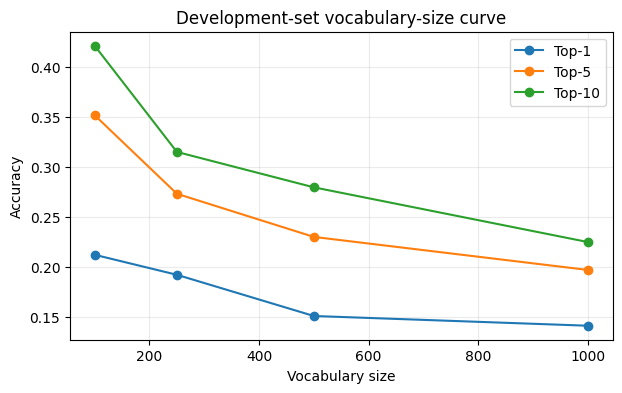

In [21]:
def vocabulary_curve(sim,indices,sizes=(100,250,500,1000),repeats=5):
    words=np.array(sorted(set(pw)))
    rows=[]
    for size in sizes:
        vals=[]
        for seed in range(repeats):
            chosen=set(np.random.default_rng(seed).choice(words,min(size,len(words)),replace=False))
            p_mask=np.array([w in chosen for w in pw])
            q_idx=np.array([i for i in indices if tw[i] in chosen],int)
            if not len(q_idx): continue
            sub_sim=sim[q_idx][:,p_mask]
            sub_pw=pw[p_mask]
            order=np.argsort(-sub_sim,axis=1)
            vals.append([np.mean([tw[i] in set(sub_pw[order[j,:k]]) for j,i in enumerate(q_idx)]) for k in (1,5,10)])
        if vals:
            m=np.mean(vals,axis=0)
            rows.append({'words':size,'uniform_random_top1':1/size,'top1':m[0],'top5':m[1],'top10':m[2]})
    return pd.DataFrame(rows)

curve=vocabulary_curve(S_all,dev_idx)
display(curve.round(4))
plt.figure(figsize=(7,4))
plt.plot(curve.words,curve.top1,marker='o',label='Top-1')
plt.plot(curve.words,curve.top5,marker='o',label='Top-5')
plt.plot(curve.words,curve.top10,marker='o',label='Top-10')
plt.xlabel('Vocabulary size'); plt.ylabel('Accuracy'); plt.title('Development-set vocabulary-size curve')
plt.grid(alpha=.25); plt.legend(); plt.show()

## 13. Class-wise performance and uncertainty

Micro Top-k accuracy weights every query clip equally. The macro result first computes accuracy per gloss and then averages across glosses, reducing the influence of classes with more query clips.

The bootstrap below resamples gloss classes, not individual clips, to reflect the grouped structure of the test data.

In [22]:
def macro_topk(sim,indices,k=1):
    order=np.argsort(-sim[indices],axis=1)
    by_class={}
    for row,i in enumerate(indices):
        hit=tw[i] in set(pw[order[row,:k]])
        by_class.setdefault(tw[i],[]).append(hit)
    return float(np.mean([np.mean(v) for v in by_class.values()]))

for k in (1,5,10):
    print(f"DEV macro Top-{k}:",round(macro_topk(S_all,dev_idx,k),4))

def class_bootstrap_ci(sim,indices,k=1,B=1000,seed=7):
    order=np.argsort(-sim[indices],axis=1)
    by_class={}
    for row,i in enumerate(indices):
        by_class.setdefault(tw[i],[]).append(tw[i] in set(pw[order[row,:k]]))
    classes=list(by_class)
    rng=np.random.default_rng(seed); vals=[]
    for _ in range(B):
        chosen=rng.choice(classes,len(classes),replace=True)
        vals.append(np.mean([np.mean(by_class[c]) for c in chosen]))
    return np.quantile(vals,[.025,.975])

for k in (1,5,10):
    lo,hi=class_bootstrap_ci(S_all,dev_idx,k)
    print(f"DEV macro Top-{k} 95% class-bootstrap CI: [{lo:.3f}, {hi:.3f}]")

DEV macro Top-1: 0.1539
DEV macro Top-5: 0.2174
DEV macro Top-10: 0.243
DEV macro Top-1 95% class-bootstrap CI: [0.120, 0.186]
DEV macro Top-5 95% class-bootstrap CI: [0.180, 0.255]
DEV macro Top-10 95% class-bootstrap CI: [0.205, 0.284]


## 14. iSign continuous-clip motion-activity diagnostics (optional)

If the previous iSign pose cache is present, this section loads it and compares the heuristic segment count with the approximate word count in the iSign metadata. This is a diagnostic, **not a ground-truth word-boundary evaluation**. A low segment-per-word ratio or weak correlation indicates that hand-speed valleys should be described as motion-activity segmentation rather than semantic word segmentation.

This section is optional for the CISLR recognition comparisons.

In [23]:
def segment_valleys(speed,smooth=5,prom_frac=.5,min_dist=10,rest_frac=.15):
    s=uniform_filter1d(speed,smooth)
    ref=np.percentile(s,90)
    active=np.where(s>rest_frac*ref)[0]
    if len(active)==0: return [],s
    a0,a1=active[0],active[-1]+1
    valleys,_=find_peaks(-s[a0:a1],prominence=prom_frac*ref,distance=min_dist)
    cuts=[a0]+list(valleys+a0)+[a1]
    segs=[(cuts[i],cuts[i+1]) for i in range(len(cuts)-1) if cuts[i+1]-cuts[i]>=min_dist]
    return segs,s

def hand_speed(a,fps=25):
    speed=np.zeros(len(a),np.float32)
    for sl in (slice(7,28),slice(28,49)):
        h=a[:,sl,:2]
        present=np.abs(h).sum((1,2))>0
        centers=np.where(present[:,None],h.mean(1),np.nan)
        v=np.r_[np.nan,np.linalg.norm(np.diff(centers,axis=0),axis=1)]*fps
        speed=np.maximum(speed,np.nan_to_num(v))
    return speed

isign_clips={}
for p in sorted(ISIGN_SAMPLE_CACHE.glob('chunk_*.npz')):
    with np.load(p) as z:
        for uid in z.files: isign_clips[uid]=z[uid].astype(np.float32)
for p in sorted(ISIGN_CACHE.glob('chunk_*.npz')):
    with np.load(p) as z:
        for uid in z.files: isign_clips[uid]=z[uid].astype(np.float32)

print("iSign cached clips available:",len(isign_clips))

iSign cached clips available: 3038


In [24]:
if isign_clips:
    # Use iSign metadata only if available locally.
    metadata_candidates=list((ROOT/'isign').glob('iSign_v1.1.csv'))
    if metadata_candidates:
        isign_meta=pd.read_csv(metadata_candidates[0])
        usable=isign_meta[isign_meta.uid.astype(str).isin(isign_clips)].copy()
        n_words=usable.text.fillna('').astype(str).str.split().str.len().to_numpy()
        n_segments=np.array([len(segment_valleys(hand_speed(isign_clips[str(uid)]))[0])
                             for uid in usable.uid])
        ratio=np.mean(n_segments/np.maximum(n_words,1))
        corr=np.corrcoef(n_segments,n_words)[0,1] if len(usable)>2 else np.nan
        print("Clips:",len(usable),"| mean heuristic segments/word:",round(float(ratio),3),
              "| correlation with word count:",round(float(corr),3))
        display(pd.DataFrame({'words':n_words,'heuristic_segments':n_segments}).describe().round(3))
    else:
        print("iSign metadata CSV not found. Pose cache loaded, but word-count diagnostic skipped.")
else:
    print("No iSign cache found. Skip this optional section; recognition experiments above are unaffected.")

Clips: 3038 | mean heuristic segments/word: 1.725 | correlation with word count: 0.403


,words,heuristic_segments
count,3038.000,3038.000
mean,8.324,7.949
std,5.161,4.572
min,0.000,0.000
25%,5.000,5.000
50%,8.000,7.000
75%,12.000,10.000
max,28.000,53.000


## 15. Save results, embeddings and model weights

Save the metadata subset, query split, comparison table, similarity matrices, Transformer weights and configuration. This makes the result reproducible and allows the prototype application to use the same preprocessing and trained encoder.

If ST-GCN was run, its weights and embeddings are saved too.

In [25]:
comparison=pd.DataFrame(results_table)
comparison.to_csv(OUT3/'comparison_results.csv',index=False)

np.savez_compressed(
    OUT3/'evaluation_split.npz',
    dev_idx=dev_idx, final_idx=final_idx,
    prototype_uids=Pr.uid.astype(str).to_numpy(),
    query_uids=Te.uid.astype(str).to_numpy(),
    prototype_glosses=pw, query_glosses=tw
)

np.savez_compressed(
    OUT3/'similarity_matrices.npz',
    handcrafted=S_all,
    transformer=S_transformer,
    **({'isign_pretrained':S_isign_pretrain} if 'S_isign_pretrain' in globals() else {}),
    **({'stgcn':S_stgcn} if 'S_stgcn' in globals() else {})
)

torch.save({
    'state_dict':transformer_model.state_dict(),
    'input_dim':100,'sequence_length':32,'seed':0,
    'epochs':TRANSFORMER_EPOCHS,'feature_definition':'trajectory + velocity + masked handshape'
},OUT3/'transformer_pose_encoder.pt')

if 'stgcn_model' in globals():
    torch.save({'state_dict':stgcn_model.state_dict(),'seed':1,'epochs':40},
               OUT3/'stgcn_pose_encoder.pt')

config={
    'title':'Pose-Based Recognition of Indian Sign Language using Deep Learning on the iSign Dataset',
    'research_question':'Can pose-based representations support low-resource ISL processing through iSign motion-activity analysis and CISLR one-shot prototype matching?',
    'seed':SEED,'words':len(valid_words),'prototypes':len(Pr),'queries':len(Te),
    'dev_fraction':DEV_FRACTION,'stride':STRIDE,'dtw_shortlist':DTW_SHORTLIST,
    'dtw_alpha_selected_on_dev':float(best_alpha),
    'test_caveat':'Earlier exploratory work inspected the full test set; held-back partition is not a pristine blind test.'
}
with open(OUT3/'experiment_config.json','w') as f: json.dump(config,f,indent=2)
print("Saved outputs to:",OUT3)

Saved outputs to: /content/drive/MyDrive/isl_project/cislr_task3


## 16. Interpretation checklist for the report

Before writing the results section, verify the following:

1. **Same split:** all model comparisons use the same prototype set and the same development / held-back query split.
2. **No overclaiming:** the Transformer’s positive pairs are two augmented views of the same prototype clip; this is not supervised same-gloss learning across signers.
3. **Segmentation wording:** unless manually annotated real iSign boundaries are available, describe the hand-speed method as a motion-activity baseline, not a validated semantic word-boundary detector.
4. **Dataset separation:** iSign and CISLR have different roles. Do not claim iSign sentence clips are labelled training examples for all CISLR recognition classes.
5. **Top-k context:** report the vocabulary size, number of prototypes, number of queries and the uniform-random Top-1 reference \(1/V\).
6. **Class balance:** report macro results or class-wise results alongside micro Top-k accuracy.
7. **Test-set caveat:** disclose that earlier exploratory experiments used the full test set before the later split.
8. **Prototype system:** keep live camera predictions separate from offline benchmark accuracy. A working webcam demo is a demonstration of the pipeline, not proof of benchmark performance.

In [26]:
!pip -q install ruptures

import ruptures as rpt
from scipy.ndimage import uniform_filter1d
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [27]:
def motion_energy(a):
    x = a[:, 3:49].astype(np.float32)
    present = np.abs(x).sum(axis=2) > 0

    diff = np.diff(x, axis=0)
    valid = present[1:] & present[:-1]

    velocity = np.linalg.norm(diff, axis=2)
    velocity[~valid] = np.nan

    energy = np.nanmedian(velocity, axis=1)
    energy = np.nan_to_num(energy, nan=0.0)

    return np.r_[energy[0], energy]

def adaptive_segments(a, smooth=5, min_duration=8, max_gap=5):
    energy = uniform_filter1d(motion_energy(a), size=smooth)

    median = np.median(energy)
    mad = np.median(np.abs(energy - median))

    low = median + 0.5 * mad
    high = median + 2 * mad

    active = False
    start = 0
    segments = []

    for i, value in enumerate(energy):
        if not active and value >= high:
            start = i
            active = True

        elif active and value < low:
            if i - start >= min_duration:
                segments.append((start, i))
            active = False

    if active and len(energy) - start >= min_duration:
        segments.append((start, len(energy)))

    merged = []
    for s, e in segments:
        if merged and s - merged[-1][1] <= max_gap:
            merged[-1] = (merged[-1][0], e)
        else:
            merged.append((s, e))

    return merged, energy

In [28]:
def pelt_segments(a, penalty=3, min_size=8):
    energy = motion_energy(a)
    energy = uniform_filter1d(energy, size=5)

    signal = energy.reshape(-1, 1)

    if len(signal) < 2 * min_size:
        return [], energy

    algo = rpt.Pelt(
        model="rbf",
        min_size=min_size,
        jump=1
    ).fit(signal)

    cuts = algo.predict(pen=penalty)

    points = [0] + cuts
    segments = [
        (points[i], points[i+1])
        for i in range(len(points)-1)
        if points[i+1] - points[i] >= min_size
    ]

    return segments, energy

In [29]:
def compare_segmentation(a):
    baseline, speed = segment_valleys(hand_speed(a))
    adaptive, energy = adaptive_segments(a)
    pelt, _ = pelt_segments(a)

    return {
        "Hand-speed": baseline,
        "Adaptive energy": adaptive,
        "PELT": pelt
    }, speed, energy

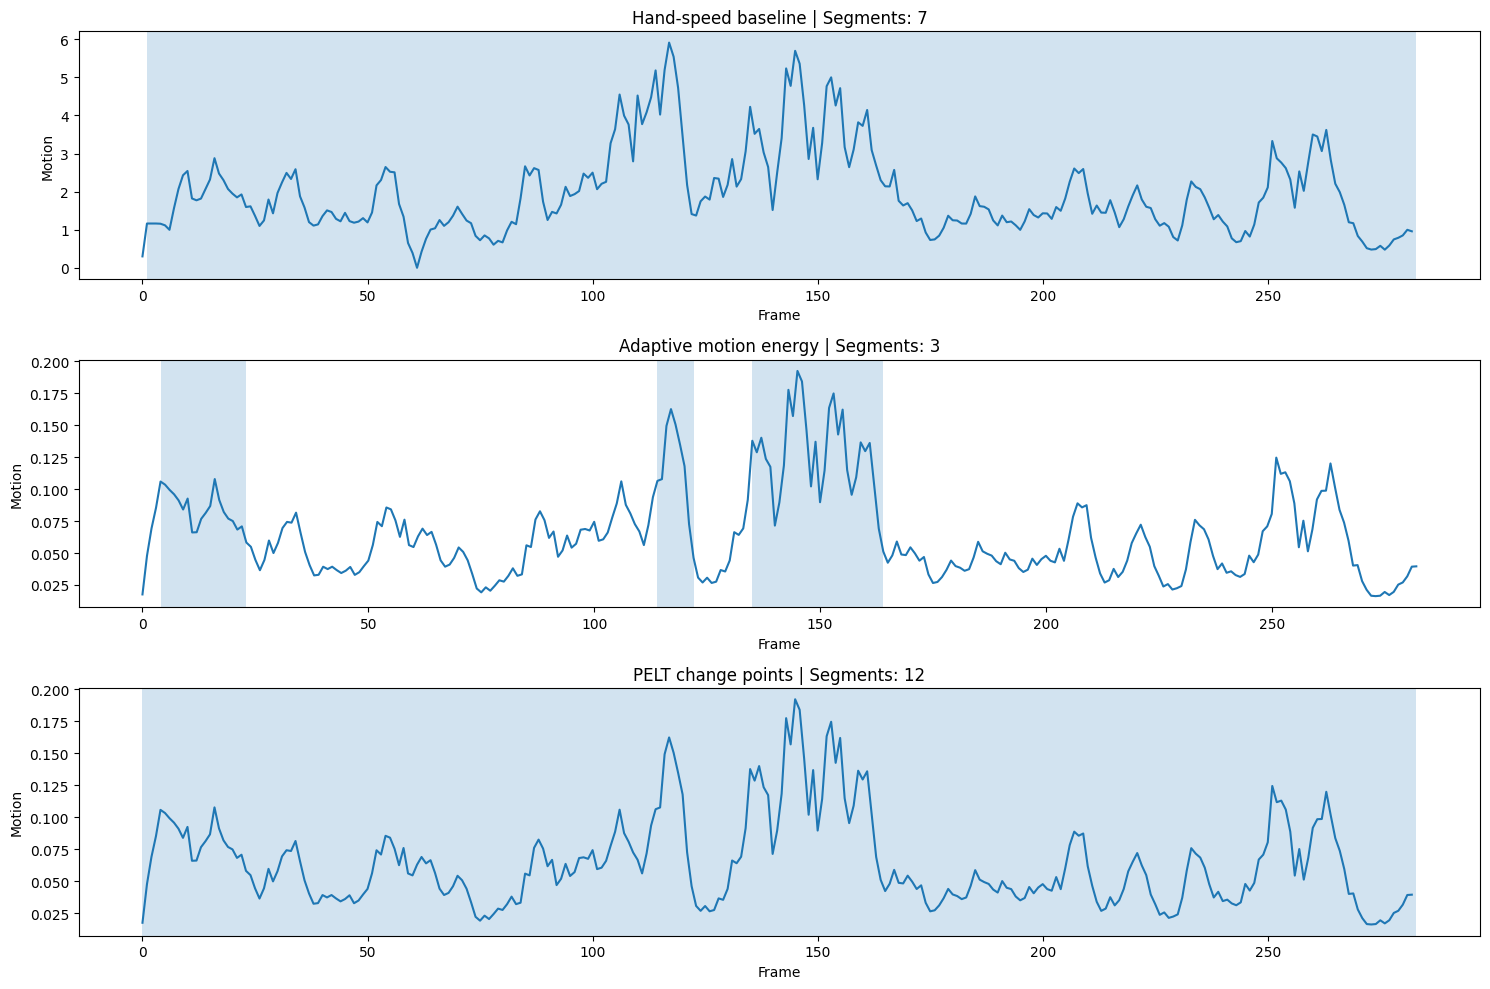

Clip: M3OUJYjZkqw--24
Hand-speed : 7 segments
Adaptive energy : 3 segments
PELT : 12 segments


In [30]:
uid = next(iter(isign_clips))
a = isign_clips[uid]

results, speed, energy = compare_segmentation(a)

fig, axes = plt.subplots(3, 1, figsize=(15, 10))

methods = [
    ("Hand-speed baseline", results["Hand-speed"], speed),
    ("Adaptive motion energy", results["Adaptive energy"], energy),
    ("PELT change points", results["PELT"], energy)
]

for ax, (name, segments, signal) in zip(axes, methods):
    ax.plot(signal)
    for start, end in segments:
        ax.axvspan(start, end, alpha=0.2)
    ax.set_title(f"{name} | Segments: {len(segments)}")
    ax.set_xlabel("Frame")
    ax.set_ylabel("Motion")

plt.tight_layout()
plt.show()

print("Clip:", uid)
for name, segments in results.items():
    print(name, ":", len(segments), "segments")

In [31]:
rows = []

sample_ids = list(isign_clips)[:100]

for uid in sample_ids:
    a = isign_clips[uid]

    base, _ = segment_valleys(hand_speed(a))
    adaptive, _ = adaptive_segments(a)
    pelt, _ = pelt_segments(a)

    rows.append({
        "uid": uid,
        "frames": len(a),
        "hand_speed": len(base),
        "adaptive_energy": len(adaptive),
        "pelt": len(pelt)
    })

seg_results = pd.DataFrame(rows)

display(seg_results.head(10))
display(seg_results[
    ["hand_speed", "adaptive_energy", "pelt"]
].describe().round(2))

/tmp/ipykernel_414/1315148499.py:11: RuntimeWarning: All-NaN slice encountered
  energy = np.nanmedian(velocity, axis=1)


,uid,frames,hand_speed,adaptive_energy,pelt
0,M3OUJYjZkqw--24,283,7,3,12
1,dac1fcc8319a-8,103,3,2,4
2,nIjAEHi-6HU--98,116,3,3,4
3,DfbGvOJJ4pQ--19,381,15,3,13
4,O9kqg-Kt6MA--33,262,9,4,13
5,aIaavgLhloE--13,122,5,2,6
6,gjuVryYRGZE--15,468,14,5,20
7,0ox5ohcu7jg--19,681,23,5,36
8,IykCj1JGO5A--104,74,3,0,4
9,myIXH3PjvoI--62,96,1,0,4


,hand_speed,adaptive_energy,pelt
count,100.00,100.00,100.00
mean,7.02,2.25,10.23
std,4.85,1.60,6.70
min,0.00,0.00,1.00
25%,3.00,1.00,5.00
50%,6.00,2.00,9.00
75%,9.00,3.00,13.00
max,25.00,7.00,36.00


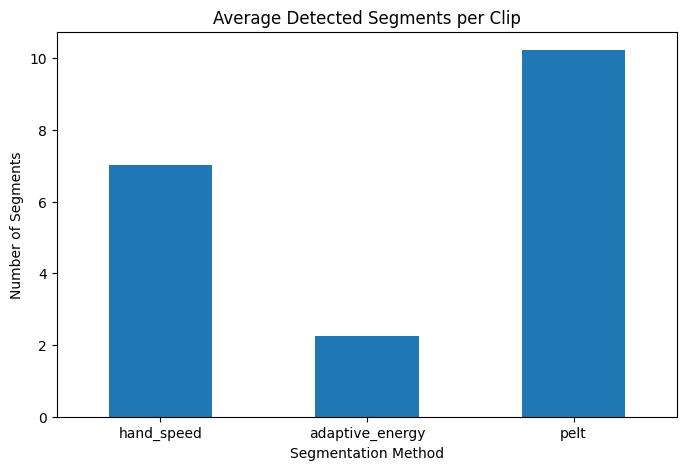

In [32]:
seg_results[
    ["hand_speed", "adaptive_energy", "pelt"]
].mean().plot(kind="bar", figsize=(8, 5))

plt.title("Average Detected Segments per Clip")
plt.ylabel("Number of Segments")
plt.xlabel("Segmentation Method")
plt.xticks(rotation=0)
plt.show()

In [33]:
seg_results.to_csv(
    OUT3 / "segmentation_comparison.csv",
    index=False
)

In [34]:
annotations = {
    "clip_id_1": [25, 61, 103, 148],
    "clip_id_2": [34, 79, 121]
}

In [35]:
def boundary_scores(predicted, actual, tolerance=5):
    predicted = sorted(predicted)
    actual = sorted(actual)

    matched = set()
    tp = 0

    for p in predicted:
        candidates = [
            (abs(p-a), i)
            for i, a in enumerate(actual)
            if i not in matched and abs(p-a) <= tolerance
        ]

        if candidates:
            _, idx = min(candidates)
            matched.add(idx)
            tp += 1

    fp = len(predicted) - tp
    fn = len(actual) - tp

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

    return precision, recall, f1

In [36]:
def get_boundaries(segments, n_frames):
    return sorted(set(
        [e for s, e in segments[:-1]]
    )) if len(segments) > 1 else []